In [2]:
from pathlib import Path
import pandas as pd

folder = next(
    (p for p in [Path("data/raw/secom"), Path("../data/raw/secom")] if p.exists()),
    None
)
if folder is None:
    raise FileNotFoundError("Can't find data/raw/secom. Check the folder location.")

X = pd.read_csv(folder / "secom.data", sep=r"\s+", header=None, na_values="NaN")
labels = pd.read_csv(
    folder / "secom_labels.data",
    sep=r"\s+",
    header=None,
    usecols=[0],
    names=["label"],
)

print("Measurements:", X.shape)
print("Pass/fail counts:")
print(labels["label"].value_counts())
print("Missing measurements:", X.isna().sum().sum())

Measurements: (1567, 590)
Pass/fail counts:
label
-1    1463
 1     104
Name: count, dtype: int64
Missing measurements: 41951


Entirely missing columns: 0
Rows with missing values: 1567


Matplotlib is building the font cache; this may take a moment.


<Axes: title={'center': '15 columns with the most missing values'}, ylabel='Missing values (%)'>

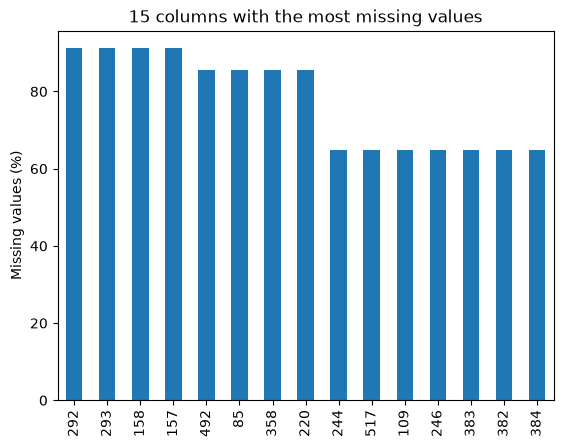

In [3]:
missing_pct = X.isna().mean().mul(100).sort_values(ascending=False)

print("Entirely missing columns:", (missing_pct == 100).sum())
print("Rows with missing values:", X.isna().any(axis=1).sum())

missing_pct.head(15).plot(
    kind="bar",
    ylabel="Missing values (%)",
    title="15 columns with the most missing values"
)

In [4]:
missing_summary = pd.DataFrame({
    "missing_count": X.isna().sum(),
    "missing_percent": X.isna().mean() * 100,
}).sort_values("missing_percent", ascending=False)

display(missing_summary.head(20).round(1))

,missing_count,missing_percent
292,1429,91.2
293,1429,91.2
158,1429,91.2
157,1429,91.2
492,1341,85.6
85,1341,85.6
358,1341,85.6
220,1341,85.6
244,1018,65.0
517,1018,65.0


In [5]:
for limit in [30, 50, 70]:
    remaining = (missing_pct <= limit).sum()
    print(f"Features with no more than {limit}% missing: {remaining} of {X.shape[1]}")

Features with no more than 30% missing: 558 of 590
Features with no more than 50% missing: 562 of 590
Features with no more than 70% missing: 582 of 590


In [6]:
keep_features = missing_pct <= 70
X_work = X.loc[:, keep_features].copy()
print("Working data shape:", X_work.shape)

Working data shape: (1567, 582)


In [7]:
labels["label"].value_counts().sort_index()

label
-1    1463
 1     104
Name: count, dtype: int64

In [8]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.model_selection import StratifiedKFold, cross_validate

# 1 means fail; 0 means pass
y = labels["label"].eq(1).astype(int)
print("Pass / fail counts:")
print(y.value_counts().sort_index().rename(index={0: "Pass", 1: "Fail"}))

model = make_pipeline(
    SimpleImputer(strategy="median"),
    StandardScaler(),
    LogisticRegression(class_weight="balanced", max_iter=3000)
)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

scores = cross_validate(
    model,
    X_work,
    y,
    cv=cv,
    scoring=["balanced_accuracy", "recall", "precision", "roc_auc"],
    n_jobs=-1
)

for metric in ["balanced_accuracy", "recall", "precision", "roc_auc"]:
    values = scores[f"test_{metric}"]
    print(f"{metric}: {values.mean():.3f} ± {values.std():.3f}")

Pass / fail counts:
label
Pass    1463
Fail     104
Name: count, dtype: int64
balanced_accuracy: 0.553 ± 0.032
recall: 0.212 ± 0.078
precision: 0.121 ± 0.030
roc_auc: 0.656 ± 0.024


In [9]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import confusion_matrix, classification_report

prob_fail = cross_val_predict(
    model,
    X_work,
    y,
    cv=cv,
    method="predict_proba",
    n_jobs=-1
)[:, 1]

pred_fail = (prob_fail >= 0.5).astype(int)

print("Confusion matrix (rows = actual, columns = predicted):")
print(confusion_matrix(y, pred_fail))
print(classification_report(y, pred_fail, target_names=["Pass", "Fail"], zero_division=0))

Confusion matrix (rows = actual, columns = predicted):
[[1308  155]
 [  82   22]]
              precision    recall  f1-score   support

        Pass       0.94      0.89      0.92      1463
        Fail       0.12      0.21      0.16       104

    accuracy                           0.85      1567
   macro avg       0.53      0.55      0.54      1567
weighted avg       0.89      0.85      0.87      1567



Baseline interpretation: With a 0.5 probability cutoff, the model identifies 22 of 104 failed examples and misses 82. It also flags 155 passing examples. Although overall accuracy is 85%, fail recall is only 0.21, so accuracy alone overstates performance on the minority fail class. These results are exploratory; they do not validate a screening threshold

Always-pass baseline: Predicting every example as Pass gives 93.4% accuracy but detects none of the 104 failures. The logistic regression model catches 22 failures, but misses 82 and flags 155 passing examples. This shows why accuracy alone is misleading for this imbalanced dataset. Results are exploratory and do not establish a validated screening method.

In [10]:
from sklearn.metrics import confusion_matrix

for cutoff in [0.20, 0.30, 0.40, 0.50]:
    pred = (prob_fail >= cutoff).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()

    precision = tp / (tp + fp) if tp + fp else 0
    recall = tp / (tp + fn) if tp + fn else 0

    print(
        f"Cutoff {cutoff:.2f}: "
        f"failures caught {tp}/104, missed {fn}, "
        f"passing examples flagged {fp}, "
        f"fail precision {precision:.2f}, fail recall {recall:.2f}"
    )

Cutoff 0.20: failures caught 28/104, missed 76, passing examples flagged 232, fail precision 0.11, fail recall 0.27
Cutoff 0.30: failures caught 25/104, missed 79, passing examples flagged 205, fail precision 0.11, fail recall 0.24
Cutoff 0.40: failures caught 22/104, missed 82, passing examples flagged 184, fail precision 0.11, fail recall 0.21
Cutoff 0.50: failures caught 22/104, missed 82, passing examples flagged 155, fail precision 0.12, fail recall 0.21


Threshold check: Lowering the probability cutoff from 0.50 to 0.20 caught 6 additional failures, but also flagged 77 more passing examples. Fail recall remained low (0.27 at the lowest cutoff tested). This is an exploratory baseline; it does not establish a suitable screening threshold.

The SECOM baseline misses most failed examples, even at the lower cutoffs tested. The capacitor data shows measurements changing during stress testing, but it does not provide confirmed good/fail labels. These findings are exploratory; neither dataset analysis currently validates a defect screening threshold.

In [12]:
from sklearn.impute import SimpleImputer
from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.metrics import confusion_matrix
from sklearn.preprocessing import StandardScaler
import numpy as np

model_40 = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("select", SelectKBest(score_func=f_classif, k=40)),
    ("scale", StandardScaler()),
    ("classifier", LogisticRegression(
        class_weight="balanced",
        max_iter=3000
    ))
])

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

prob_fail_40 = cross_val_predict(
    model_40, X_work, y,
    cv=cv,
    method="predict_proba",
    n_jobs=-1
)[:, 1]

for cutoff in [0.20, 0.30, 0.40, 0.50]:
    pred = (prob_fail_40 >= cutoff).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, pred, labels=[0, 1]).ravel()
    precision = tp / (tp + fp) if tp + fp else 0
    recall = tp / (tp + fn) if tp + fn else 0

    print(
        f"Cutoff {cutoff:.2f}: failures caught {tp}/104, missed {fn}, "
        f"passing examples flagged {fp}, fail precision {precision:.2f}, "
        f"fail recall {recall:.2f}"
    )

Cutoff 0.20: failures caught 88/104, missed 16, passing examples flagged 946, fail precision 0.09, fail recall 0.85
Cutoff 0.30: failures caught 80/104, missed 24, passing examples flagged 705, fail precision 0.10, fail recall 0.77
Cutoff 0.40: failures caught 66/104, missed 38, passing examples flagged 508, fail precision 0.11, fail recall 0.63
Cutoff 0.50: failures caught 58/104, missed 46, passing examples flagged 355, fail precision 0.14, fail recall 0.56


40-feature model: Selecting 40 features within each cross-validation fold improved failure recall compared with the initial model. At a 0.50 cutoff, it caught 58 of 104 failures and flagged 355 passing examples. At 0.20, it caught 88 failures but flagged 946 passes. This shows the tradeoff between catching failures and producing false alarms; the results do not establish a suitable screening cutoff.

In [13]:
from sklearn.metrics import confusion_matrix

for name, probabilities in [
    ("Initial model", prob_fail),
    ("40-feature model", prob_fail_40),
]:
    print(name)
    for cutoff in [0.20, 0.30, 0.40, 0.50]:
        predicted = (probabilities >= cutoff).astype(int)
        tn, fp, fn, tp = confusion_matrix(y, predicted, labels=[0, 1]).ravel()
        recall = tp / (tp + fn) if tp + fn else 0
        print(
            f"  cutoff {cutoff:.2f}: "
            f"caught {tp}/104 failures, missed {fn}, "
            f"flagged {fp} passes, recall {recall:.2f}"
        )

Initial model
  cutoff 0.20: caught 28/104 failures, missed 76, flagged 232 passes, recall 0.27
  cutoff 0.30: caught 25/104 failures, missed 79, flagged 205 passes, recall 0.24
  cutoff 0.40: caught 22/104 failures, missed 82, flagged 184 passes, recall 0.21
  cutoff 0.50: caught 22/104 failures, missed 82, flagged 155 passes, recall 0.21
40-feature model
  cutoff 0.20: caught 88/104 failures, missed 16, flagged 946 passes, recall 0.85
  cutoff 0.30: caught 80/104 failures, missed 24, flagged 705 passes, recall 0.77
  cutoff 0.40: caught 66/104 failures, missed 38, flagged 508 passes, recall 0.63
  cutoff 0.50: caught 58/104 failures, missed 46, flagged 355 passes, recall 0.56


Model comparison: Selecting 40 features improved failure recall across the tested cutoffs. At a 0.30 cutoff, it caught 80 of 104 failures but flagged 705 passing examples. The initial model caught 25 failures and flagged 205 passes. This is a tradeoff: the 40-feature model misses fewer failures but creates many more false alarms. These results are exploratory and do not establish a validated screening method.

## Conclusion

The SECOM data has 104 failures among 1,567 examples and many missing measurements. In this exploratory test, the 40-feature model caught more failures than the initial model, but it also flagged many more passing examples. The capacitor data shows measurements changing during stress testing, but it does not provide confirmed good/fail labels. Neither analysis validates a defect-screening threshold. Further work needs verified labels, confirmed measurement meanings, and testing on separate data.